# Анализ результатов A/B-тестирования новой платежной воронки интернет-магазина (Азия)

**Информация о заказчике**: крупный интернет-магазин, который работает преимущественно в Азии. Магазин недавно провёл А/B-тест, чтобы проверить новую платёжную воронку.

**Гипотеза** продакт-менеджера заключается в том, что новая платёжная воронка увеличит конверсию в покупку.

**Нулевая гипотеза** $H_0: pB <= pA$. Конверсия в тествой группе B с новой платежной воронкой не превышает (меньше или равно) конверсию в контрольной группе А со старой платежной воронкой.<br> 

**Альтернативная гипотеза** $pB > pA$ <br> Конверсия в тестовой группе B с новой платежной воронкой статистически значимо превышает конверсию в контрольной группе А со старой платежной воронкой.

**Задача аналитика** : проанализировать результаты А/B-теста под названием `new_payment_funnel_test_summer_2025`

**Данные**

- `new_users_test_2025.csv` — данные всех пользователей, зарегистрировавшихся в интернет-магазине с 1 по 14 июня 2025 года.
    - `user_id` — уникальный идентификатор пользователя;
    - `first_date` — дата регистрации;
    - `region` — регион, к которому относится пользователь;
    - `device` — устройство, с которого происходила регистрация.

- `sessions_test_2025.csv` — данные всех сессий новых пользователей с 1 по 21 июня 2025 года.
    - `user_id` — уникальный идентификатор пользователя;
    - `session_start` — дата начала сессии;
    - `session_duration` — длительность сессии в минутах.

- `purchases_test_2025.csv` — данные всех покупок новых пользователей с 1 по 21 июня 2025 года.
    - `user_id` — уникальный идентификатор пользователя;
    - `event_dt` — дата и время покупки;
    - `revenue` — стоимость покупки в долларах.

- `participants_test_2025.csv` — данные участников тестов.
    - `user_id` — уникальный идентификатор пользователя;
    - `group` — группа А/B-теста;
    - `ab_test` — название А/B-теста.

**Содержание проекта**
1. Загрузка и подготовка данных
2. Исследовательский анализ данных теста
3. Проверка гипотез
4. Формулирование выводов и рекомендаций

## 1. Загрузка и подготовка данных

In [1]:
# Установка библиотеки для форматирования кода
%pip install jupyter_black

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Загрузка библиотек для работы
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import jupyter_black
from scipy import stats
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from statsmodels.stats.proportion import proportions_ztest


plt.style.use("ggplot")
plt.rcParams["figure.figsize"] = (12, 6)
jupyter_black.load()

In [3]:
# данныe о всех пользователей, зарегистрировавшихся в интернет-магазине с 1 по 14 июня 2025 года
new_users_test = pd.read_csv(
    r"C:\Users\Pavel\Desktop\Пет проекты Analitycs\Анализ результатов АB-теста интернет-магазина (Азия)\new_users_test_2025.csv",
    parse_dates=["first_date"],
)

# данные всех сессий новых пользователей с 1 по 21 июня 2025 года
session_test = pd.read_csv(
    r"C:\Users\Pavel\Desktop\Пет проекты Analitycs\Анализ результатов АB-теста интернет-магазина (Азия)\sessions_test_2025.csv",
    parse_dates=["session_start"],
)

# данные всех покупок новых пользователей с 1 по 21 июня 2025 года
purchases_test = pd.read_csv(
    r"C:\Users\Pavel\Desktop\Пет проекты Analitycs\Анализ результатов АB-теста интернет-магазина (Азия)\purchases_test_2025.csv",
    parse_dates=["event_dt"],
)

# данные участников тестов
participants_test = pd.read_csv(
    r"C:\Users\Pavel\Desktop\Пет проекты Analitycs\Анализ результатов АB-теста интернет-магазина (Азия)\participants_test_2025.csv"
)

In [4]:
# Просмотр содержимого датасетов
display(
    new_users_test.sample(2),
    session_test.sample(2),
    purchases_test.sample(2),
    participants_test.sample(2),
)

,user_id,first_date,region,device
51921,845EDDC7E214C3A7,2025-06-30,Southeast Asia,iPhone
78845,8A297087638429E9,2025-06-05,East Asia,iPhone


,user_id,session_start,session_duration
131485,308CD0475FDE1A35,2025-06-13 03:15:54,1.00
5729,7868304E1F4653A7,2025-06-01 08:01:42,2.54


,user_id,event_dt,revenue
45562,EDE3CDFA09C2E699,2025-06-15 12:15:58,499.99
27545,4BEC4F92D26F3048,2025-06-10 06:05:57,4.99


,user_id,group,ab_test
1198,56C2903DDEA8E26A,A,new_payment_funnel_test_summer_2025
444,4C1C865D70A75669,A,new_payment_funnel_test_summer_2025


In [5]:
# Информация об объеме датасетов
new_users_test.info()
session_test.info()
purchases_test.info()
participants_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 131486 entries, 0 to 131485
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   user_id     131486 non-null  object        
 1   first_date  131486 non-null  datetime64[ns]
 2   region      131486 non-null  object        
 3   device      131486 non-null  object        
dtypes: datetime64[ns](1), object(3)
memory usage: 4.0+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 491443 entries, 0 to 491442
Data columns (total 3 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   user_id           491443 non-null  object        
 1   session_start     491443 non-null  datetime64[ns]
 2   session_duration  491443 non-null  float64       
dtypes: datetime64[ns](1), float64(1), object(1)
memory usage: 11.2+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149152 entries, 0 to 149151
Da

Датасеты имеют корректное название столбцов и в них отсутсвуют пропуски.

### Проверка на пересечение пользователей между тестами и группами 

In [6]:
a = participants_test[participants_test["group"] == "A"]["user_id"].unique()
b = participants_test[participants_test["group"] == "B"]["user_id"].unique()

cross_users_all = list(set(a) & set(b))

need_test_a = participants_test[
    (participants_test["group"] == "A")
    & (participants_test["ab_test"] == "new_payment_funnel_test_summer_2025")
]["user_id"].unique()
need_test_b = participants_test[
    (participants_test["group"] == "B")
    & (participants_test["ab_test"] == "new_payment_funnel_test_summer_2025")
]["user_id"].unique()

cross_users = list(set(need_test_a) & set(need_test_b))

print(
    f"Количество пересекающихся пользователей между тестами и группами: {len(cross_users_all)}"
)
print(
    f"Количество пересекающихся пользователей между группами в нужном нам тесте new_payment_funnel_test_summer_2025: {len(cross_users)}"
)

Количество пересекающихся пользователей между тестами и группами: 0
Количество пересекающихся пользователей между группами в нужном нам тесте new_payment_funnel_test_summer_2025: 0


### Проверка на равномерность распределения пользователей по группам

In [7]:
# Оставим в датасете только пользователей из нужного нам теста new_payment_funnel_test_summer_2025
participants_test = participants_test[
    participants_test["ab_test"] == "new_payment_funnel_test_summer_2025"
]

test_a = participants_test[participants_test["group"] == "A"]["user_id"].nunique()
test_b = participants_test[participants_test["group"] == "B"]["user_id"].nunique()

print(f"Количество пользователей в группе А: {test_a}, в группе B: {test_b}")
print(f"Абсолютная разница между группами: {test_a - test_b}")
print(
    f"Относительная разница между группами: {round((test_a - test_b)/test_a * 100, 4)}%"
)

Количество пользователей в группе А: 1598, в группе B: 1468
Абсолютная разница между группами: 130
Относительная разница между группами: 8.1352%


In [8]:
# Оставим в остальных таблицах только участников теста
test_new_users = new_users_test[
    new_users_test["user_id"].isin(participants_test["user_id"])
].merge(participants_test, on="user_id")

test_sessions = session_test[
    session_test["user_id"].isin(participants_test["user_id"])
].merge(participants_test, on="user_id")

test_purchases = purchases_test[
    purchases_test["user_id"].isin(participants_test["user_id"])
].merge(participants_test, on="user_id")

### Количество пользователей по региону и девайсам

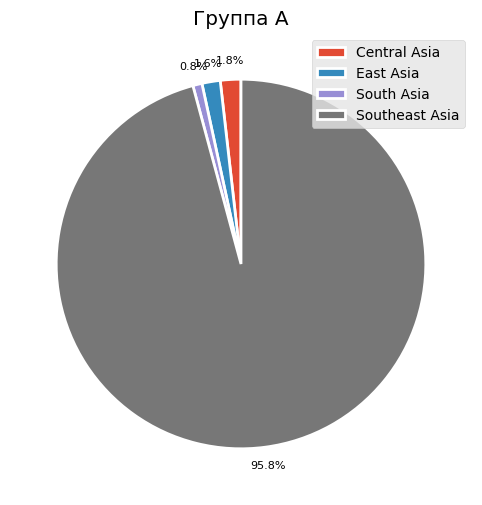

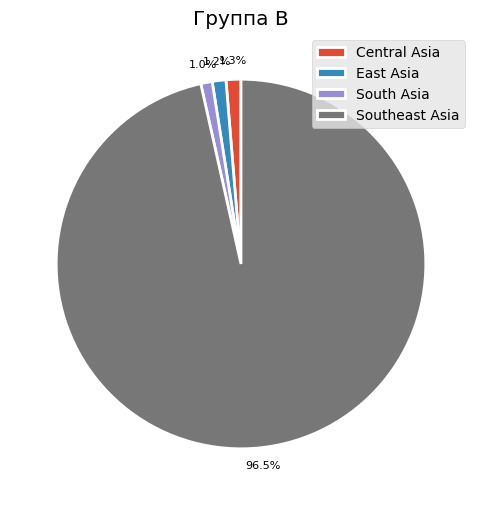

In [9]:
# Количество уникальных пользователей по группам и региону
users_by_group_region = test_new_users.groupby(["group", "region"])["user_id"].nunique()

share_region = (
    (users_by_group_region / users_by_group_region.groupby("group").transform("sum"))
    .round(3)
    .reset_index()
)

for group in share_region["group"].unique():
    subset = share_region[share_region["group"] == group]
    subset.plot(
        kind="pie",
        y="user_id",
        labels=subset["region"],
        ylabel="",
        legend=True,
        startangle=90,
        autopct="%1.1f%%",
        pctdistance=1.1,
        fontsize=8,
        labeldistance=None,
        wedgeprops={"edgecolor": "white", "linewidth": 2},
        title=f"Группа {group}",
    )

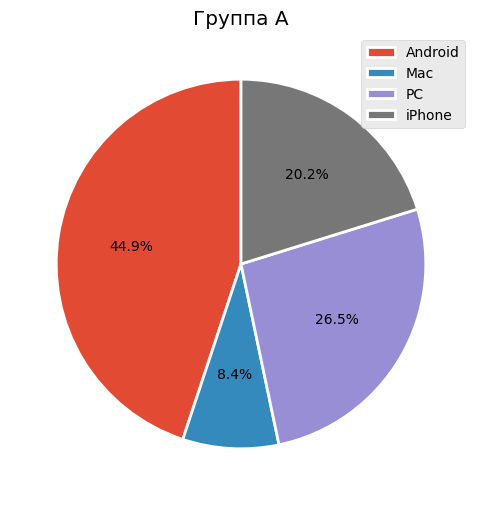

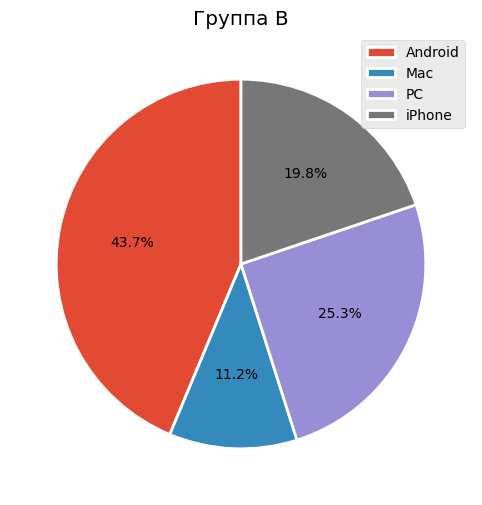

In [10]:
# Количество уникальных пользователей по группам и девайсу
users_by_group_device = test_new_users.groupby(["group", "device"])["user_id"].nunique()

share_device = (
    (users_by_group_device / users_by_group_device.groupby("group").transform("sum"))
    .round(3)
    .reset_index()
)

for group in share_device["group"].unique():
    subset = share_device[share_device["group"] == group]
    subset.plot(
        kind="pie",
        y="user_id",
        labels=subset["device"],
        ylabel="",
        legend=True,
        startangle=90,
        autopct="%1.1f%%",
        fontsize=10,
        labeldistance=None,
        wedgeprops={"edgecolor": "white", "linewidth": 2},
        title=f"Группа {group}",
    )

Контрольная и тестовая группы сходятся в распределении по региону и устройствам. Это означает, что рандомизация прошла успешно. Большинство пользователей находятся в Южной Азии (~96%) и чаще используют Android в качестве устройства (~44%)

## 2. Исследовательский анализ данных теста

### 2.1 График кумулятивной динамики метрик и их анализ

#### График кумулятивной динамики количества новых пользователей по группам и дате

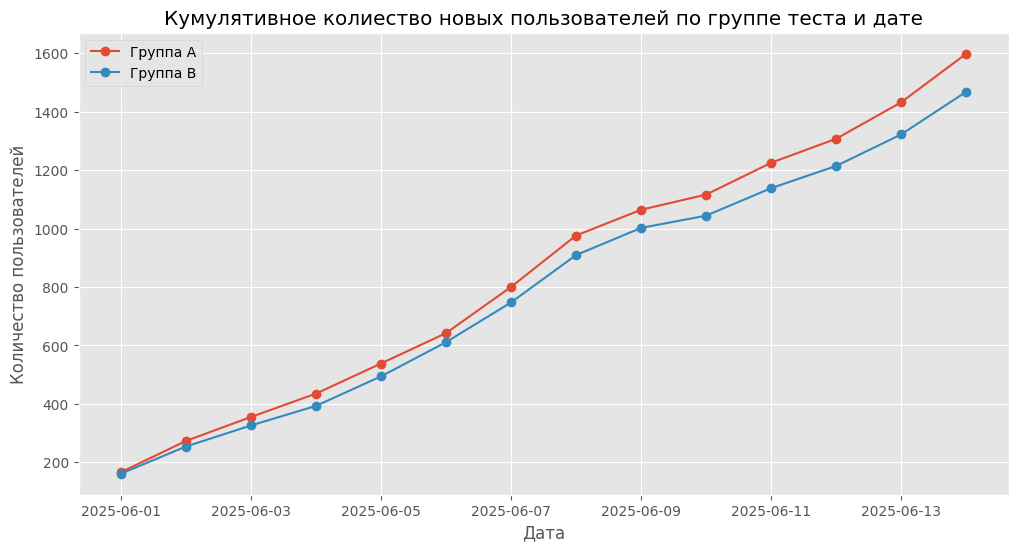

In [11]:
# Группируем данные по дате и группе, получаем ежедневное количество новых пользователей
cumsum_new_users = test_new_users.groupby(["first_date", "group"]).agg(
    {"user_id": "nunique"}
)

# Считаем кумулятивное количество пользователей с помощью функции cumsum
cumsum_new_users = (
    cumsum_new_users.groupby(["group"])["user_id"]
    .cumsum()
    .reset_index()
    .rename(columns={"user_id": "cumsum_users"})
)

# Строим график накопительной динамики новых пользователей по группам
for group in cumsum_new_users["group"].unique():
    grp_data = cumsum_new_users[cumsum_new_users["group"] == group]
    plt.plot(
        grp_data["first_date"],
        grp_data["cumsum_users"],
        marker="o",
        label=f"Группа {group}",
    )
plt.title("Кумулятивное колиество новых пользователей по группе теста и дате")
plt.xlabel("Дата")
plt.ylabel("Количество пользователей")
plt.legend()
plt.show()

#### График кумулятивной динамики сессий

In [ ]:
# Добавим новый столбец, оставив только дату сессии (без времени)
test_sessions["session_start_date"] = test_sessions["session_start"].dt.date

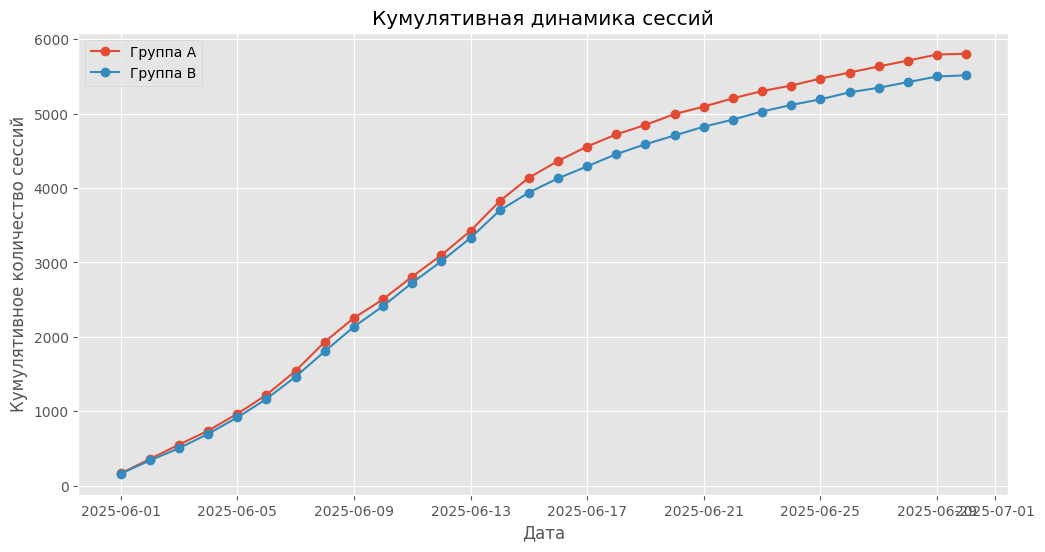

In [24]:
# Группируем данные по дате начала сессии и тестовой группе, считаем количество сессий
cumsum_sessions = (
    test_sessions.groupby(["session_start_date", "group"])["user_id"]
    .size()
    .reset_index(name="sessions_count")
)

# Вычисляем кумулятивное количество сессий для каждой группы
cumsum_sessions["cumsum_sessions"] = cumsum_sessions.groupby("group")[
    "sessions_count"
].cumsum()

for group in cumsum_sessions["group"].unique():
    grp_data_2 = cumsum_sessions[cumsum_sessions["group"] == group]
    plt.plot(
        grp_data_2["session_start_date"],
        grp_data_2["cumsum_sessions"],
        marker="o",
        label=f"Группа {group}",
    )
plt.xlabel("Дата")
plt.ylabel("Кумулятивное количество сессий")
plt.title("Кумулятивная динамика сессий")
plt.legend()
plt.show()

Предварительный вывод по графикам: во всех рассматриваемых метриках (новые пользователи и сессии) результаты группы A немного лучше результатов группы B. Визуально разница не кажется огромной, но она устойчиво сохраняется на протяжении теста.

#### Сравнение конверсии в контрольной и тестовой группе

In [ ]:
# Cчитаем по группам пользователей, совершивших покупку
purchase_users = test_purchases.groupby("group")["user_id"].nunique()

# Cчитаем общее количество пользователей по группам
total_users = test_new_users.groupby("group")["user_id"].nunique()

# Рассчитаем конверсию
conversion = (
    (purchase_users / total_users).reset_index().rename(columns={0: "conversion"})
)

print("Конверсия по группам (покупатели / всего пользователей)")
conversion

Конверсия по группам (покупатели / всего пользователей)


,group,user_id
0,A,0.295369
1,B,0.183924


Результаты показывают, что конверсия группы A (29.5%) значительно выше по сравнению с группой B (18.4%). Это может говорить о том, что текущий вариант платежной воронки в контрольной группе A более эффективен в совершении покупок после регистрации, чем новый вариант платежной воронки в тестовой группе В.

### Кумулятивная динамика покупок 

In [ ]:
# Добавим новый столбец, оставив только дату покупки (без времени)
test_purchases["event_dt_date"] = test_purchases["event_dt"].dt.date

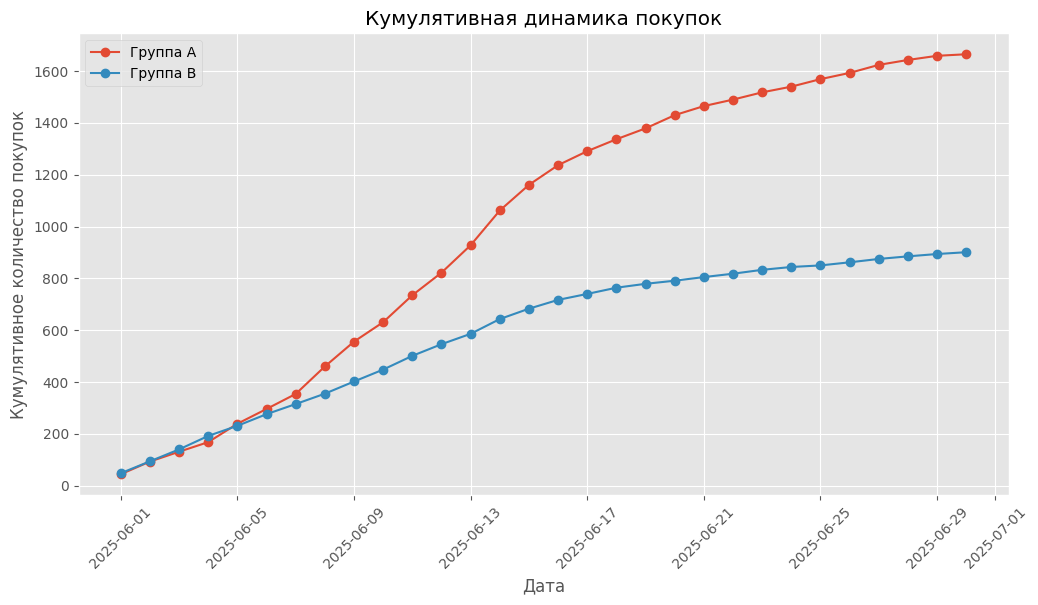

In [39]:
cumsum_purchases = (
    test_purchases.groupby(["event_dt_date", "group"])
    .size()
    .reset_index(name="purchase_count")
)

cumsum_purchases["cumsum_purchases"] = cumsum_purchases.groupby("group")[
    "purchase_count"
].cumsum()

for group in cumsum_purchases["group"].unique():
    grp_data_3 = cumsum_purchases[cumsum_purchases["group"] == group]
    plt.plot(
        grp_data_3["event_dt_date"],
        grp_data_3["cumsum_purchases"],
        marker="o",
        label=f"Группа {group}",
    )
plt.xlabel("Дата")
plt.ylabel("Кумулятивное количество покупок")
plt.title("Кумулятивная динамика покупок")
plt.legend()
plt.xticks(rotation=45)
plt.show()

До 2025-06-07 рост покупок был практически одинаковым у обоих групп. Однако после 7 июня более активно стали совершать покупки пользователи из контрольной группы А (со старой платежной воронкой).

Для окончательных выводов требуется провести статистический тест для конверсий групп А и B, который покажет является ли эта разница статистически значимой.

Так как конверсия это долевая метрика, для нее подойдет z-тест пропорций.

## 3. Проверка гипотезы

Сформулированные гипотезы:

**Нулевая гипотеза** $H_0: pB <= pA$. Конверсия в тествой группе B с новой платежной воронкой не превышает (меньше или равно) конверсию в контрольной группе А со старой платежной воронкой.<br> 

**Альтернативная гипотеза** $pB > pA$ <br> Конверсия в тестовой группе B с новой платежной воронкой статистически значимо превышает конверсию в контрольной группе А со старой платежной воронкой.

Проверить то, что размер выборки соответсвует требованиям не представляется возможным, так как мы не знаем MDE и базовую конверсию до проведения A/B-теста. Можем проверить лишь предпосылку о достаточном количестве данных в выборках для z-теста пропорций.

#### Предварительный расчет конверсий в группах и их сравнение

In [ ]:
# Общее количество пользователей в каждой группе
n_a, n_b = total_users.values[0], total_users.values[1]

# Количество пользователей, совершивших покупку, в каждой группе
m_a, m_b = purchase_users.values[0], purchase_users.values[1]

# Конверсия (покупатели / все пользователи) в группах
p_a, p_b = m_a / n_a, m_b / n_b

print(f"Размер выборки группы А = {n_a}, B = {n_b}")
print(f"Количество пользователей, совершивших покупку в группе А = {m_a}, B = {m_b}")
print(f"Конверсия в группе А = {p_a}, B = {p_b}")
print(f"Относительная разница между группами = {round(abs(p_a-p_b) / p_a * 100, 4)}%")
print(f"Абсолютная разница между группами = {round((p_a-p_b) * 100, 4)} п.п.")

# Проверка предпосылки о достаточном количестве данных в выборках
if (
    (p_a * n_a > 10)
    and ((1 - p_a) * n_a > 10)
    and (p_b * n_b > 10)
    and ((1 - p_b) * n_b > 10)
):
    print("Предпосылка о достаточном количестве данных выполняется")
else:
    print("Предпосылка о достаточном количестве данных НЕ выполняется")

Размер выборки группы А = 1598, B = 1468
Количество пользователей, совершивших покупку в группе А = 472, B = 270
Конверсия в группе А = 0.295369211514393, B = 0.18392370572207084
Относительная разница между группами = 37.7309%
Абсолютная разница между группами = 11.1446 п.п.
Предпосылка о достаточном количестве данных выполняется


По предварительным расчетам видно, что в **тестовой группе В** с новой платежной воронкой **конверсия ниже на 11,14 п.п**, чем в **контрольной группе А** со старой платежной воронкой.

При таких результатах не имеет смысла проверять односторонюю альтернативную гипотезу **$pB > pA$**, так как конверсия в группе B однозначно ниже.

Имеет смысл проверить двустороннюю альтернативную гипотезу **$pB ≠ pA$**, то есть насколько статистически значима любая разница конверсии в группах.

In [ ]:
alpha = 0.05

z_stat, p_value = proportions_ztest([m_a, m_b], [n_a, n_b])

print(f"pvalue = {p_value:.3f}")

if p_value >= alpha:
    print(
        f"Недостаточно оснований отклонить нулевую гипотезу, разница между группами А и В статистически не значима"
    )
else:
    print(
        f"Альтернативная гипотеза pB ≠ pA находит подтверждение, разница между группами статистически значима"
    )

pvalue = 0.000
Альтернативная гипотеза pB ≠ pA находит подтверждение, разница между группами статистически значима


## 4. Формулирование выводов и рекомендаций

**Выводы:** 

- Тест был проведён в соответствии с ТЗ с небольшими, практически незначительными отклонениями по распределению пользователей по регионам и устройству.

- Между группам наблюдается статистически значимая разница: **в контрольной группе А** со старой платежной воронкой конверсия **29.53%**, **в тестовой группе В** с новой платежной воронкой конверсия **18.39%** . Абсолютная разница между группами **11.14 п.п.**

**Рекомендации:**

- Новая платежная воронка работает хуже, чем старая. Это видно по предварительным расчетам конверсии (A **29.53%** vs B **18.39%**). Однозначно не стоит внедрять ее для всех пользователей.

- Конверсия снизилась — можно предположить, что в момент первой покупки у части пользователей возникают технические сложности, и этот момент нужно протестировать.